<a href="https://colab.research.google.com/github/VedVar43789/TumorSense/blob/main/notebooks/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

In [3]:
data = load_breast_cancer(as_frame=True)
df = data.data
df['target'] = data.target

In [4]:
display(df.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
df.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'target'],
      dtype='object')

In [6]:
# df.isnull().sum() # no missing values

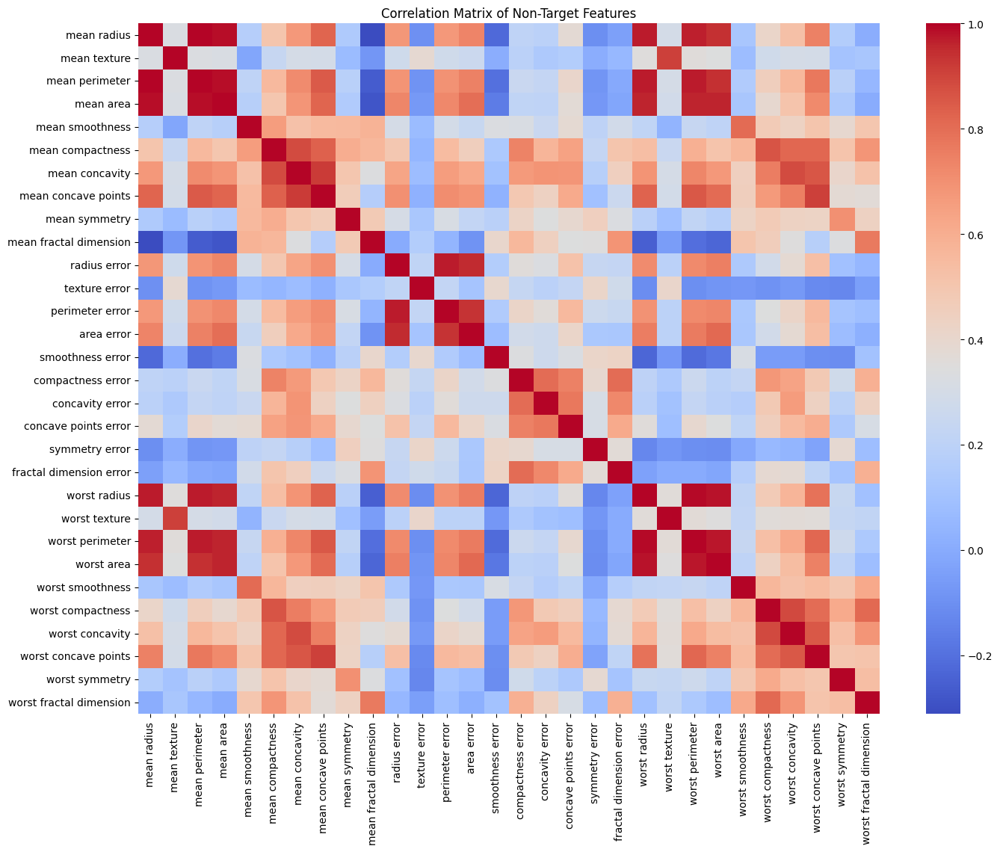

In [7]:
# Correlation matrix over non-target features
non_target_features = df.drop(columns=['target'])
corr_matrix = non_target_features.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title("Correlation Matrix of Non-Target Features")
plt.show()

In [8]:
from sklearn.feature_selection import f_classif

# Perform ANOVA (F-value) between each feature and the target
f_values, p_values = f_classif(non_target_features, df['target'])

anova_df = pd.DataFrame({
    'Feature': non_target_features.columns,
    'F_Value': f_values,
    'P_Value': p_values
}).sort_values('F_Value', ascending=False)

print("ANOVA Results (Top Features by F-Value):")
display(anova_df)

ANOVA Results (Top Features by F-Value):


,Feature,F_Value,P_Value
27,worst concave points,964.385393,1.969100e-124
22,worst perimeter,897.944219,5.771397e-119
7,mean concave points,861.676020,7.101150e-116
20,worst radius,860.781707,8.482292e-116
2,mean perimeter,697.235272,8.436251e-101
23,worst area,661.600206,2.828848e-97
0,mean radius,646.981021,8.465941e-96
3,mean area,573.060747,4.734564e-88
6,mean concavity,533.793126,9.966556e-84
26,worst concavity,436.691939,2.464664e-72


In [10]:
# Warning: Plotting all pairwise relationships for 30 features will create 900 plots.
# This may take a long time to execute and render.

# Using seaborn pairplot to plot all combinations of 2 features with a regression line
sns.pairplot(non_target_features, kind='reg',
             plot_kws={'line_kws':{'color':'red'}, 'scatter_kws': {'alpha': 0.1, 's': 5}})
plt.show()

In [11]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each non-target feature
vif_data = pd.DataFrame()
vif_data["Feature"] = non_target_features.columns

# Calculating VIF for each feature
vif_data["VIF"] = [variance_inflation_factor(non_target_features.values, i)
                   for i in range(len(non_target_features.columns))]

# Sort the results to see the highest VIF values first
vif_data = vif_data.sort_values(by="VIF", ascending=False).reset_index(drop=True)

print("Variance Inflation Factor (VIF):")
display(vif_data)

Variance Inflation Factor (VIF):


,Feature,VIF
0,mean radius,63306.172036
1,mean perimeter,58123.586079
2,worst radius,9674.742602
3,worst perimeter,4487.781270
4,mean area,1287.262339
5,worst area,1138.759252
6,mean fractal dimension,629.679874
7,worst fractal dimension,423.396723
8,mean smoothness,393.398166
9,worst smoothness,375.597155
